In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from ipynb.fs.full.model import build_nn_model, train_model, plot_loss, plot_mae, evaluate_model 

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import tensorflow as tf

<h1>Further Training the 16th Oct Basic MLP on 27th Data </h1>
standard" - normalising inputs and outputs using StandardScaler() 

<h3>Importing The Data

,Unnamed: 0,point,time,x,y,x_rb,y_rb,s0,s1,s2,...,track_cy,track_radius,roi_x_min,roi_y_min,roi_x_max,roi_y_max,cx_rel,cy_rel,cx_mm,cy_mm
0,0.0,0.0,1.272900,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,...,254.0,6.0,152.0,114.0,432.0,394.0,-1.0,0.0,0.009091,0.000000
1,1.0,1.0,2.764900,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,...,254.0,6.0,154.0,114.0,434.0,394.0,1.0,0.0,-0.009091,0.000000
2,2.0,0.0,23.054501,1.2,1.2,1.200032,1.2,6144.0,-8393.0,2249.0,...,62.0,6.0,-64.0,-78.0,216.0,202.0,-217.0,-192.0,1.972727,1.745455
3,3.0,1.0,25.128901,1.1,1.2,1.099897,1.2,6144.0,-7949.0,1805.0,...,64.0,6.0,-48.0,-76.0,232.0,204.0,-201.0,-190.0,1.827273,1.727273
4,4.0,2.0,27.203501,1.0,1.2,0.999989,1.2,6144.0,-7506.0,1362.0,...,68.0,6.0,-32.0,-72.0,248.0,208.0,-185.0,-186.0,1.681818,1.690909


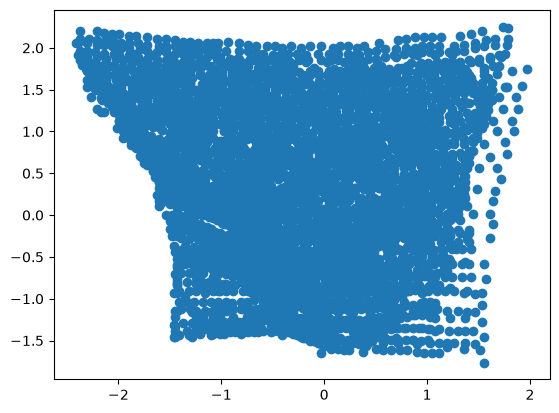

In [2]:
data_concat = pd.read_csv("processed_data/27Oct_data.csv", dtype="float32") #data was saved as float32, by default this was importing as float64
display(data_concat.head())
plt.scatter(data_concat["cx_mm"], data_concat["cy_mm"])

<h3>Correcting The Data - Removing NANs

In [3]:
data_concat.isna().sum()

Unnamed: 0        0
point             0
time              0
x                 0
y                 0
x_rb              0
y_rb              0
s0                0
s1                0
s2                0
strain            0
frame_id          0
n_circles         0
cx              170
cy              170
radius          170
detected          0
track_cx          1
track_cy          1
track_radius      1
roi_x_min         1
roi_y_min         1
roi_x_max         1
roi_y_max         1
cx_rel          170
cy_rel          170
cx_mm           170
cy_mm           170
dtype: int64

In [4]:
data_concat = data_concat.dropna()

<h3>Scale new training data

In [7]:
dataset = data_concat[["cx_mm", "cy_mm", "s0", "s1", "s2"]].reset_index(drop=True) #reset indexes as multiple datapoints combined
inputs = data_concat[["cx_mm", "cy_mm"]]
outputs = data_concat[["s0", "s1", "s2"]]

In [8]:
scalerX = StandardScaler().fit(inputs)
scalerY = StandardScaler().fit(outputs)

X_scaled = scalerX.transform(inputs)
y_scaled = scalerY.transform(outputs)

<h2> Load 16th Oct Model

In [15]:
model = tf.keras.models.load_model("models/16Oct_MLP_2_model.keras")

W0000 00:00:1793724555.885848  334505 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


In [16]:
X_train_scaled, X_test_scaled, y_train_scaled, y_test_scaled = train_test_split(
    X_scaled, y_scaled, test_size=0.2, random_state=42
)

In [17]:
history = train_model(model, X_train_scaled, y_train_scaled, verbose=1)

Epoch 1/100
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0189 - mae: 0.0958 - val_loss: 0.0170 - val_mae: 0.0914
Epoch 2/100
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0180 - mae: 0.0924 - val_loss: 0.0164 - val_mae: 0.0880
Epoch 3/100
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0178 - mae: 0.0921 - val_loss: 0.0197 - val_mae: 0.1051
Epoch 4/100
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0179 - mae: 0.0920 - val_loss: 0.0162 - val_mae: 0.0900
Epoch 5/100
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0176 - mae: 0.0909 - val_loss: 0.0160 - val_mae: 0.0869
Epoch 6/100
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0174 - mae: 0.0908 - val_loss: 0.0168 - val_mae: 0.0908
Epoch 7/100
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0178 - mae: 0.0919 - val_loss: 0.0183 - val_mae: 0.0993
Epoch 8/100
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0177 - mae: 0.0919 - val_loss: 0.0163 - val_mae: 0.0892
Epoch 9/100
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.017

In [18]:
y_pred = model.predict(X_test_scaled, verbose=0)
evaluate_model("Neural Network", y_test_scaled, y_pred, is_scaled=True)


Neural Network Results (scaled):
  Overall R2:  0.9799
  Weighted R2: 0.9796


(0.9798920750617981, 0.9796260595321655)

<h2> Saving the model

In [ ]:
model.save('models/27+16Oct_MLP_scaled_model.keras')

<h3> Evaluating the Model further

0.01658734120428562


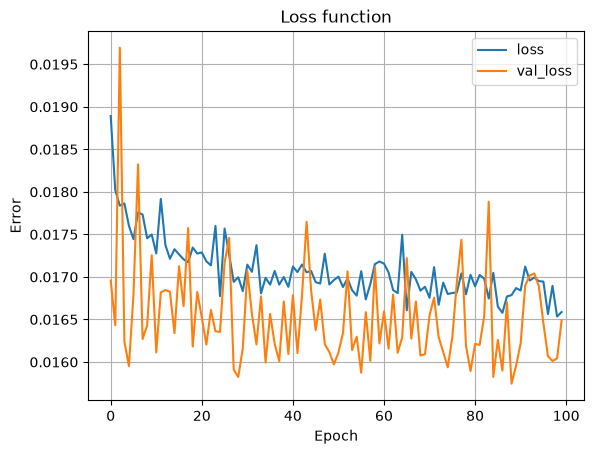

In [19]:
plot_loss(history)
print(history.history['loss'][-1])

0.08725953102111816


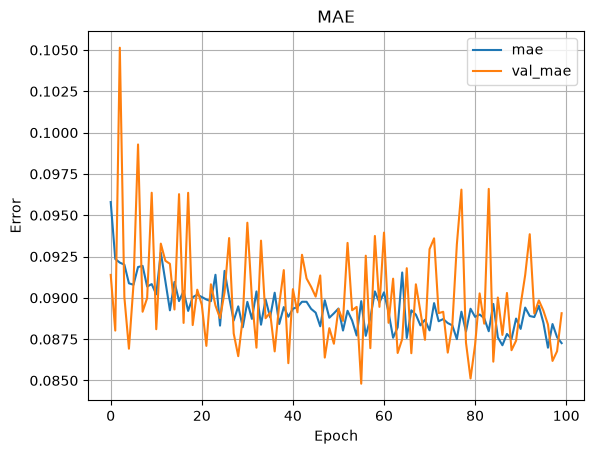

In [20]:
plot_mae(history)
print(history.history['mae'][-1])

In [21]:
test_results_dnn_standard = model.evaluate(X_test_scaled, y_test_scaled, verbose=0)
test_results_dnn_standard

[0.020099638029932976, 0.09590541571378708]

794 794


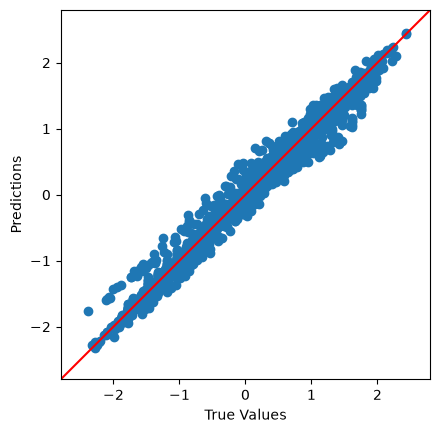

In [22]:
#make predictions with dnn model
#y_pred = model.predict(X_test_scaled, verbose=0)

a = plt.axes(aspect='equal')
plt.scatter(y_test_scaled, y_pred)
plt.xlabel('True Values')
plt.ylabel('Predictions')
lims = [-2.8, 2.8]
plt.xlim(lims)
plt.ylim(lims)
_ = plt.plot(lims, lims, color="red")
plt.title("")
print(len(y_test_scaled), len(y_pred))

Text(0.5, 0.98, '16th Oct Test Predictions not flattened')

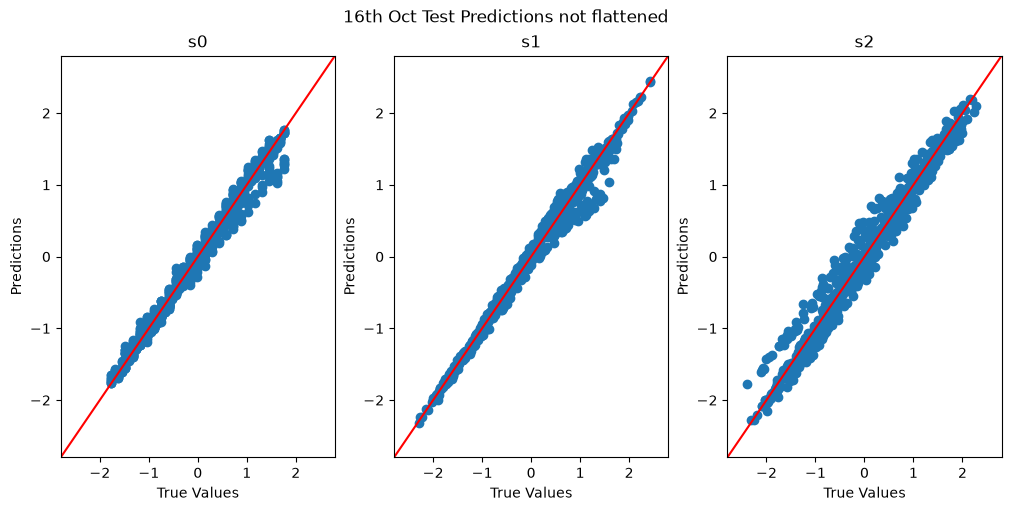

In [23]:
fig, axs = plt.subplots(1, 3, figsize=(10,5), constrained_layout=True)
for i, label in enumerate(['s0', 's1', 's2']):
    axs[i].scatter(y_test_scaled[:, i], y_pred[:, i])
    lims = [-2.8, 2.8]
    axs[i].set_xlabel('True Values')
    axs[i].set_ylabel('Predictions')
    axs[i].set_xlim(lims)
    axs[i].set_ylim(lims)
    _ = axs[i].plot(lims, lims, color="red")
    axs[i].set_title(label)
fig.suptitle("16th Oct Test Predictions not flattened")

<h3> Look at the data transformed back to raw motor counts

In [24]:
y_pred_inverse = scalerY.inverse_transform(y_pred)
y_test_inverse = scalerY.inverse_transform(y_test_scaled)

794 794


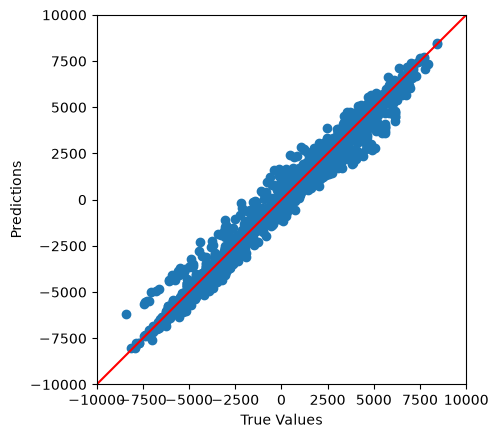

In [25]:
a = plt.axes(aspect='equal')
plt.scatter(y_test_inverse, y_pred_inverse)
plt.xlabel('True Values')
plt.ylabel('Predictions')
lims = [-10000, 10000]
plt.xlim(lims)
plt.ylim(lims)
_ = plt.plot(lims, lims, color="red")
plt.title("")
print(len(y_test_scaled), len(y_pred))

Text(0.5, 0.98, '16th Oct Test Predictions not flattened')

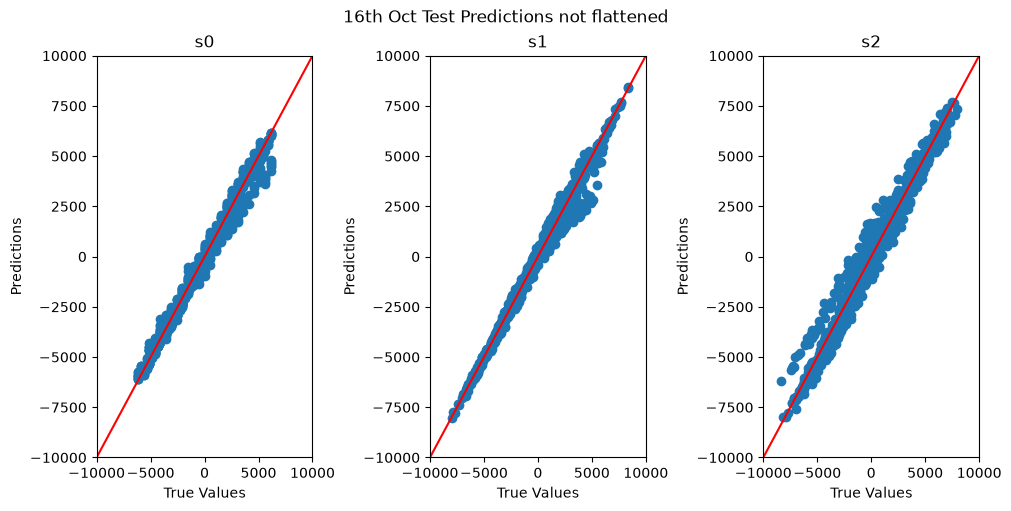

In [ ]:
fig, axs = plt.subplots(1, 3, figsize=(10,5), constrained_layout=True)
for i, label in enumerate(['s0', 's1', 's2']):
    axs[i].scatter(y_test_inverse[:, i], y_pred_inverse[:, i])
    lims = [-10000, 10000]
    axs[i].set_xlabel('True Values')
    axs[i].set_ylabel('Predictions')
    axs[i].set_xlim(lims)
    axs[i].set_ylim(lims)
    _ = axs[i].plot(lims, lims, color="red")
    axs[i].set_title(label)
fig.suptitle("27th Oct Test Predictions not flattened")

<h2> Predicting for normal square - snake



In [27]:
mesh0045_27Oct = pd.read_csv("processed_data/27Oct_0045_mesh.csv")
mesh0045_27Oct_nonans = mesh0045_27Oct.dropna()

input_27Oct_45 = mesh0045_27Oct_nonans[["cx_mm","cy_mm"]]
true_values_27Oct_45 = mesh0045_27Oct_nonans[["s0","s1","s2"]]

pred_27Oct_45_not_flat = model.predict(input_27Oct_45)

input_27Oct_45_scaled = scalerX.transform(mesh0045_27Oct_nonans[["cx_mm","cy_mm"]])
true_values_27Oct_45 = mesh0045_27Oct_nonans[["s0","s1","s2"]]
true_values_27Oct_45_scaled = scalerY.transform(true_values_27Oct_45)

pred_27Oct_45_scaled = model.predict(input_27Oct_45_scaled)

19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 838us/step
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


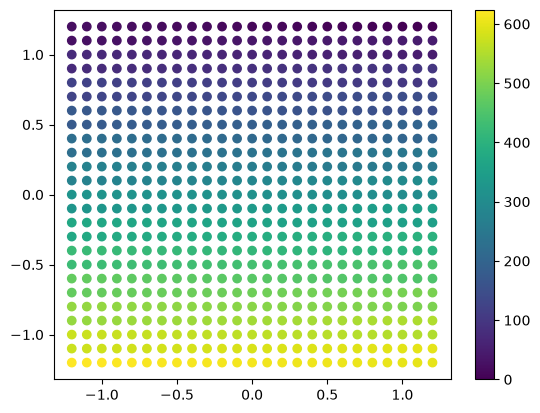

In [28]:
plt.scatter(mesh0045_27Oct["x"], mesh0045_27Oct["y"], c=mesh0045_27Oct["point"])
plt.colorbar()

In [29]:
snake_predictions = model.predict(mesh0045_27Oct[["x", "y"]])

20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 958us/step


In [30]:
snake_pred_inverse = scalerY.inverse_transform(snake_predictions)

In [31]:
print(snake_pred_inverse)
np.savetxt("predictions/27+16Oct_MLP_Scaled_Pred_snake_mesh.csv", snake_pred_inverse, delimiter=',')

[[ 4105.1978  -5450.8096   1338.8156 ]
 [ 4197.957   -5243.483    1049.964  ]
 [ 4267.9497  -5007.1235    730.58685]
 ...
 [-4488.508    6716.6343  -2291.776  ]
 [-4475.5083   7016.13    -2601.862  ]
 [-4536.1523   7284.2554  -2820.983  ]]
